# Local GPU Conjugate Gradient Benchmark

## Objective
Evaluate the performance and scalability of the Conjugate Gradient (CG)
method on the local NVIDIA GTX 1080 GPU and compare it with CPU execution.

## Hardware
- CPU: Dual Intel Xeon E5-2667 v4
- RAM: 128 GB
- GPU: NVIDIA GeForce GTX 1080 (8 GB)
- CUDA Toolkit: 12.2

## Experimental Configuration
- Matrix: Sparse symmetric positive definite (SPD)
- Storage: Compressed Sparse Row (CSR)
- Precision: Float64
- Tolerance: 1e-6
- Matrix sizes: 1,000, 5,000, 10,000, 20,000, 50,000

In [1]:
import os

cuda_path = r"C:\Program Files\NVIDIA GPU Computing Toolkit\CUDA\v12.2"

os.environ["CUDA_HOME"] = cuda_path
os.environ["CUDA_PATH"] = cuda_path

os.environ["PATH"] = (
    cuda_path + r"\bin;" +
    cuda_path + r"\nvvm\bin;" +
    os.environ["PATH"]
)

os.environ["NUMBA_CUDA_NVVM"] = (
    cuda_path + r"\nvvm\bin\nvvm64_40_0.dll"
)

os.environ["NUMBA_CUDA_LIBDEVICE"] = (
    cuda_path + r"\nvvm\libdevice\libdevice.10.bc"
)

print("CUDA paths configured")  

CUDA paths configured


In [2]:
from scipy.sparse import diags
import numpy as np
from numba import cuda

def generate_matrix(n):
    diagonals = [
        -np.ones(n - 1),
         2 * np.ones(n),
        -np.ones(n - 1)
    ]

    A = diags(
        diagonals,
        offsets=[-1, 0, 1],
        format="csr",
        dtype=np.float64
    )

    x_true = np.ones(n, dtype=np.float64)
    b = A @ x_true

    return A, x_true, b


# Initial test
n = 1000
A, x_true, b = generate_matrix(n)

print("Matrix size:", A.shape)
print("Non-zero elements:", A.nnz)
print("Data type:", A.dtype)
print("Symmetric:", (A - A.T).nnz == 0)
print("RHS shape:", b.shape)

Matrix size: (1000, 1000)
Non-zero elements: 2998
Data type: float64
Symmetric: True
RHS shape: (1000,)


In [3]:
@cuda.jit
def csr_spmv(values, col_indices, row_ptr, x, y, n):
    row = cuda.grid(1)

    if row < n:
        row_sum = 0.0

        for j in range(row_ptr[row], row_ptr[row + 1]):
            row_sum += values[j] * x[col_indices[j]]

        y[row] = row_sum


@cuda.jit
def dot_product_kernel(a, b, partial, n):
    tid = cuda.threadIdx.x
    idx = cuda.grid(1)

    shared = cuda.shared.array(256, dtype=np.float64)

    value = 0.0

    if idx < n:
        value = a[idx] * b[idx]

    shared[tid] = value
    cuda.syncthreads()

    stride = cuda.blockDim.x // 2

    while stride > 0:
        if tid < stride:
            shared[tid] += shared[tid + stride]

        cuda.syncthreads()
        stride //= 2

    if tid == 0:
        partial[cuda.blockIdx.x] = shared[0]


@cuda.jit
def vector_update(a, b, result, alpha, operation, n):
    i = cuda.grid(1)

    if i < n:
        if operation == 0:
            result[i] = a[i] + alpha * b[i]

        elif operation == 1:
            result[i] = a[i] - alpha * b[i]

        elif operation == 2:
            result[i] = alpha * a[i]

In [4]:
def gpu_conjugate_gradient(A, b, tol=1e-6, max_iter=10000):

    n = len(b)
    dtype = np.float64

    # Convert CSR matrix arrays to float64 / int32
    values = cuda.to_device(A.data.astype(dtype))
    col_indices = cuda.to_device(A.indices.astype(np.int32))
    row_ptr = cuda.to_device(A.indptr.astype(np.int32))

    # Transfer vectors to GPU
    d_b = cuda.to_device(b.astype(dtype))
    d_x = cuda.to_device(np.zeros(n, dtype=dtype))

    d_r = cuda.device_array(n, dtype=dtype)
    d_p = cuda.device_array(n, dtype=dtype)
    d_Ap = cuda.device_array(n, dtype=dtype)

    threads = 256
    blocks = (n + threads - 1) // threads

    d_partial = cuda.device_array(blocks, dtype=dtype)

    # Initial values
    d_r.copy_to_device(d_b)
    d_p.copy_to_device(d_b)

    dot_product_kernel[blocks, threads](
        d_r, d_r, d_partial, n
    )

    rs_old = np.sum(d_partial.copy_to_host())
    initial_norm = np.sqrt(rs_old)

    if initial_norm == 0:
        return d_x.copy_to_host(), 0, 0.0

    for iteration in range(max_iter):

        # Ap = A * p
        csr_spmv[blocks, threads](
            values, col_indices, row_ptr,
            d_p, d_Ap, n
        )

        # pAp = p.T * Ap
        dot_product_kernel[blocks, threads](
            d_p, d_Ap, d_partial, n
        )

        pAp = np.sum(d_partial.copy_to_host())

        if pAp <= 0:
            raise ValueError("Matrix may not be positive definite.")

        alpha = rs_old / pAp

        # x = x + alpha * p
        vector_update[blocks, threads](
            d_x, d_p, d_x, alpha, 0, n
        )

        # r = r - alpha * Ap
        vector_update[blocks, threads](
            d_r, d_Ap, d_r, alpha, 1, n
        )

        # New residual
        dot_product_kernel[blocks, threads](
            d_r, d_r, d_partial, n
        )

        rs_new = np.sum(d_partial.copy_to_host())
        residual_norm = np.sqrt(rs_new)

        if residual_norm <= tol * initial_norm:

            # Verify true residual
            csr_spmv[blocks, threads](
                values, col_indices, row_ptr,
                d_x, d_Ap, n
            )

            Ax = d_Ap.copy_to_host()
            true_residual = np.linalg.norm(b - Ax)

            if true_residual <= tol * initial_norm:
                return (
                    d_x.copy_to_host(),
                    iteration + 1,
                    true_residual
                )

            # Residual replacement
            true_r = b - Ax
            d_r.copy_to_device(true_r)
            d_p.copy_to_device(true_r)

            dot_product_kernel[blocks, threads](
                d_r, d_r, d_partial, n
            )

            rs_old = np.sum(d_partial.copy_to_host())
            continue

        beta = rs_new / rs_old

        # p = r + beta * p
        vector_update[blocks, threads](
            d_r, d_p, d_p, beta, 0, n
        )

        rs_old = rs_new

    return d_x.copy_to_host(), max_iter, np.sqrt(rs_old)

In [5]:
x_gpu, gpu_iterations, gpu_residual = gpu_conjugate_gradient(A, b)

solution_error = np.linalg.norm(x_true - x_gpu)
relative_residual = gpu_residual / np.linalg.norm(b)

print("Local GPU: GTX 1080")
print("-----------------------------")
print("Matrix size:", A.shape[0])
print("Iterations:", gpu_iterations)
print("Relative residual:", relative_residual)
print("Solution error:", solution_error)
print("Converged:", relative_residual < 1e-6)

c:\Users\ML Lab\AppData\Local\Programs\Python\Python311\Lib\site-packages\numba\cuda\dispatcher.py:536: NumbaPerformanceWarning: Grid size 4 will likely result in GPU under-utilization due to low occupancy.
  warn(NumbaPerformanceWarning(msg))
c:\Users\ML Lab\AppData\Local\Programs\Python\Python311\Lib\site-packages\numba\cuda\dispatcher.py:536: NumbaPerformanceWarning: Grid size 4 will likely result in GPU under-utilization due to low occupancy.
  warn(NumbaPerformanceWarning(msg))
c:\Users\ML Lab\AppData\Local\Programs\Python\Python311\Lib\site-packages\numba\cuda\dispatcher.py:536: NumbaPerformanceWarning: Grid size 4 will likely result in GPU under-utilization due to low occupancy.
  warn(NumbaPerformanceWarning(msg))


Local GPU: GTX 1080
-----------------------------
Matrix size: 1000
Iterations: 500
Relative residual: 3.669260810376201e-13
Solution error: 1.1320862088232394e-12
Converged: True


In [6]:
import time

# Warm-up run
gpu_conjugate_gradient(A, b)

# Benchmark
start = time.perf_counter()

x_gpu, gpu_iterations, gpu_residual = gpu_conjugate_gradient(A, b)

end = time.perf_counter()

gpu_time_ms = (end - start) * 1000

print("GTX 1080 Benchmark")
print("--------------------------")
print("Matrix size:", A.shape[0])
print("Execution time:", round(gpu_time_ms, 4), "ms")
print("Iterations:", gpu_iterations)
print("Residual:", gpu_residual)

GTX 1080 Benchmark
--------------------------
Matrix size: 1000
Execution time: 889.9625 ms
Iterations: 500
Residual: 5.189118401918117e-13


In [8]:
import pandas as pd
baseline_result = {
    "GPU": "GTX 1080",
    "Matrix_Size": A.shape[0],
    "NNZ": A.nnz,
    "Iterations": gpu_iterations,
    "Execution_Time_ms": gpu_time_ms,
    "Relative_Residual": gpu_residual / np.linalg.norm(b),
    "Solution_Error": np.linalg.norm(x_true - x_gpu)
}

print(pd.DataFrame([baseline_result]).to_string(index=False))

     GPU  Matrix_Size  NNZ  Iterations  Execution_Time_ms  Relative_Residual  Solution_Error
GTX 1080         1000 2998         500           877.5507       3.669261e-13    1.132086e-12


In [7]:
@cuda.jit
def dot_product_single_block(a, b, result, n):

    tid = cuda.threadIdx.x
    shared = cuda.shared.array(256, dtype=np.float64)

    value = 0.0

    for i in range(tid, n, cuda.blockDim.x):
        value += a[i] * b[i]

    shared[tid] = value
    cuda.syncthreads()

    stride = cuda.blockDim.x // 2

    while stride > 0:
        if tid < stride:
            shared[tid] += shared[tid + stride]

        cuda.syncthreads()
        stride //= 2

    if tid == 0:
        result[0] = shared[0]

**Optimized CG Solver**

In [8]:
def gpu_conjugate_gradient_optimized(A, b, tol=1e-6, max_iter=10000):

    n = len(b)
    dtype = np.float64

    # Transfer matrix and vectors
    d_values = cuda.to_device(A.data.astype(dtype))
    d_col_indices = cuda.to_device(A.indices.astype(np.int32))
    d_row_ptr = cuda.to_device(A.indptr.astype(np.int32))

    d_b = cuda.to_device(b.astype(dtype))
    d_x = cuda.to_device(np.zeros(n, dtype=dtype))

    d_r = cuda.device_array(n, dtype=dtype)
    d_p = cuda.device_array(n, dtype=dtype)
    d_Ap = cuda.device_array(n, dtype=dtype)

    threads = 256
    blocks = (n + threads - 1) // threads

    d_partial = cuda.device_array(1, dtype=dtype)

    d_r.copy_to_device(d_b)
    d_p.copy_to_device(d_b)

    # Initial residual
    dot_product_single_block[1, threads](
        d_r, d_r, d_partial, n
    )

    rs_old = d_partial.copy_to_host()[0]
    initial_norm = np.sqrt(rs_old)

    if initial_norm == 0:
        return d_x.copy_to_host(), 0, 0.0

    for iteration in range(max_iter):

        csr_spmv[blocks, threads](
            d_values, d_col_indices, d_row_ptr,
            d_p, d_Ap, n
        )

        dot_product_single_block[1, threads](
            d_p, d_Ap, d_partial, n
        )

        pAp = d_partial.copy_to_host()[0]

        if pAp <= 0:
            raise ValueError("Matrix may not be positive definite.")

        alpha = rs_old / pAp

        vector_update[blocks, threads](
            d_x, d_p, d_x, alpha, 0, n
        )

        vector_update[blocks, threads](
            d_r, d_Ap, d_r, alpha, 1, n
        )

        dot_product_single_block[1, threads](
            d_r, d_r, d_partial, n
        )

        rs_new = d_partial.copy_to_host()[0]

        if np.sqrt(rs_new) <= tol * initial_norm:

            csr_spmv[blocks, threads](
                d_values, d_col_indices, d_row_ptr,
                d_x, d_Ap, n
            )

            Ax = d_Ap.copy_to_host()
            true_r = b - Ax
            true_norm = np.linalg.norm(true_r)

            if true_norm <= tol * initial_norm:
                return d_x.copy_to_host(), iteration + 1, true_norm

            d_r.copy_to_device(true_r)
            d_p.copy_to_device(true_r)

            dot_product_single_block[1, threads](
                d_r, d_r, d_partial, n
            )

            rs_old = d_partial.copy_to_host()[0]
            continue

        beta = rs_new / rs_old

        vector_update[blocks, threads](
            d_r, d_p, d_p, beta, 0, n
        )

        rs_old = rs_new

    return d_x.copy_to_host(), max_iter, np.sqrt(rs_old)

In [9]:
x_opt, opt_iterations, opt_residual = gpu_conjugate_gradient_optimized(A, b)

opt_error = np.linalg.norm(x_true - x_opt)

print("Optimized GTX 1080 CG")
print("-----------------------------")
print("Iterations:", opt_iterations)
print("Relative Residual:", opt_residual / np.linalg.norm(b))
print("Solution Error:", opt_error)
print("Converged:", opt_residual / np.linalg.norm(b) < 1e-6)

c:\Users\ML Lab\AppData\Local\Programs\Python\Python311\Lib\site-packages\numba\cuda\dispatcher.py:536: NumbaPerformanceWarning: Grid size 1 will likely result in GPU under-utilization due to low occupancy.
  warn(NumbaPerformanceWarning(msg))


Optimized GTX 1080 CG
-----------------------------
Iterations: 500
Relative Residual: 3.7578760811321316e-13
Solution Error: 2.349471948975825e-13
Converged: True


In [12]:
import time

# Warm-up
gpu_conjugate_gradient_optimized(A, b)

# Repeat benchmark
times = []

for _ in range(5):
    start = time.perf_counter()

    x_opt, opt_iterations, opt_residual = (
        gpu_conjugate_gradient_optimized(A, b)
    )

    end = time.perf_counter()
    times.append((end - start) * 1000)

optimized_time_ms = np.mean(times)

print("Optimized GTX 1080 Benchmark")
print("-----------------------------")
print("Individual runs (ms):", np.round(times, 3))
print("Average time:", round(optimized_time_ms, 3), "ms")
print("Minimum time:", round(min(times), 3), "ms")
print("Maximum time:", round(max(times), 3), "ms")
print("Speedup:", round(gpu_time_ms / optimized_time_ms, 2), "x")

Optimized GTX 1080 Benchmark
-----------------------------
Individual runs (ms): [ 919.939  909.381 1066.664 1015.927 1044.83 ]
Average time: 991.348 ms
Minimum time: 909.381 ms
Maximum time: 1066.664 ms
Speedup: 0.89 x


In [13]:
optimization_results = pd.DataFrame([
    {
        "Method": "Original GPU CG",
        "Execution_Time_ms": gpu_time_ms,
        "Iterations": gpu_iterations
    },
    {
        "Method": "Single-block Reduction",
        "Execution_Time_ms": optimized_time_ms,
        "Iterations": opt_iterations
    }
])

optimization_results["Speedup"] = (
    gpu_time_ms / optimization_results["Execution_Time_ms"]
)

display(optimization_results)

,Method,Execution_Time_ms,Iterations,Speedup
0,Original GPU CG,877.55070,500,1.000000
1,Single-block Reduction,991.34834,500,0.885209


**GPU Benchmark**

In [14]:
import pandas as pd
import time
matrix_sizes = [1000, 5000, 10000, 20000, 50000]

local_gpu_results = []

for n in matrix_sizes:

    print(f"\nRunning matrix size: {n}")

    A_test, x_test, b_test = generate_matrix(n)

    try:
        start = time.perf_counter()

        x_result, iterations, residual = gpu_conjugate_gradient(
            A_test, b_test
        )

        execution_time = (time.perf_counter() - start) * 1000

        relative_residual = residual / np.linalg.norm(b_test)
        solution_error = np.linalg.norm(x_test - x_result)

        result = {
            "GPU": "GTX 1080",
            "Matrix_Size": n,
            "NNZ": A_test.nnz,
            "Iterations": iterations,
            "Execution_Time_ms": execution_time,
            "Relative_Residual": relative_residual,
            "Solution_Error": solution_error,
            "Converged": relative_residual < 1e-6
        }

        local_gpu_results.append(result)

        print("Execution time:", round(execution_time, 3), "ms")
        print("Iterations:", iterations)
        print("Relative residual:", relative_residual)
        print("Converged:", result["Converged"])

    except Exception as e:
        print(f"Failed for matrix size {n}: {e}")
        break

local_gpu_df = pd.DataFrame(local_gpu_results)
display(local_gpu_df)


Running matrix size: 1000
Execution time: 877.599 ms
Iterations: 500
Relative residual: 3.669260810376201e-13
Converged: True

Running matrix size: 5000


c:\Users\ML Lab\AppData\Local\Programs\Python\Python311\Lib\site-packages\numba\cuda\dispatcher.py:536: NumbaPerformanceWarning: Grid size 20 will likely result in GPU under-utilization due to low occupancy.
  warn(NumbaPerformanceWarning(msg))


Execution time: 4496.094 ms
Iterations: 2500
Relative residual: 7.166349994205381e-12
Converged: True

Running matrix size: 10000


c:\Users\ML Lab\AppData\Local\Programs\Python\Python311\Lib\site-packages\numba\cuda\dispatcher.py:536: NumbaPerformanceWarning: Grid size 40 will likely result in GPU under-utilization due to low occupancy.
  warn(NumbaPerformanceWarning(msg))


Execution time: 8929.986 ms
Iterations: 5000
Relative residual: 1.950309758083352e-11
Converged: True

Running matrix size: 20000


c:\Users\ML Lab\AppData\Local\Programs\Python\Python311\Lib\site-packages\numba\cuda\dispatcher.py:536: NumbaPerformanceWarning: Grid size 79 will likely result in GPU under-utilization due to low occupancy.
  warn(NumbaPerformanceWarning(msg))


Execution time: 17262.652 ms
Iterations: 10000
Relative residual: 4.256616807242888e-11
Converged: True

Running matrix size: 50000
Execution time: 18260.464 ms
Iterations: 10000
Relative residual: 9.999000099989908e-05
Converged: False


,GPU,Matrix_Size,NNZ,Iterations,Execution_Time_ms,Relative_Residual,Solution_Error,Converged
0,GTX 1080,1000,2998,500,877.5988,3.669261e-13,1.132086e-12,True
1,GTX 1080,5000,14998,2500,4496.0942,7.166350e-12,2.969077e-12,True
2,GTX 1080,10000,29998,5000,8929.9862,1.950310e-11,6.928879e-12,True
3,GTX 1080,20000,59998,10000,17262.6516,4.256617e-11,1.512238e-11,True
4,GTX 1080,50000,149998,10000,18260.4643,9.999000e-05,1.914846e+02,False


In [12]:
gtx_repeated_results = []

matrix_sizes = [1000, 5000, 10000, 20000, 50000]

for n in matrix_sizes:

    A_test, x_test, b_test = generate_matrix(n)

    # Warm-up run (excluded from measurements)
    gpu_conjugate_gradient(
        A_test, b_test, tol=1e-6, max_iter=50000
    )

    print(f"\nGTX 1080 Benchmark: {n} x {n}")

    for run in range(1, 4):

        start = time.perf_counter()

        x_result, iterations, residual = gpu_conjugate_gradient(
            A_test,
            b_test,
            tol=1e-6,
            max_iter=50000
        )

        execution_time = (time.perf_counter() - start) * 1000

        # Independent true residual verification
        true_residual = np.linalg.norm(b_test - A_test @ x_result)
        relative_residual = true_residual / np.linalg.norm(b_test)

        result = {
            "Matrix_Size": n,
            "Run": run,
            "Iterations": iterations,
            "Execution_Time_ms": execution_time,
            "Relative_Residual": relative_residual,
            "Solution_Error": np.linalg.norm(x_test - x_result),
            "Converged": relative_residual < 1e-6
        }

        gtx_repeated_results.append(result)

        print(
            f"Run {run}: {execution_time:.2f} ms | "
            f"Iterations: {iterations} | "
            f"Residual: {relative_residual:.3e} | "
            f"Converged: {result['Converged']}"
        )

gtx_repeated_df = pd.DataFrame(gtx_repeated_results)

gtx_repeated_df.to_csv(
    "repeated_gtx1080_results.csv",
    index=False
)

display(gtx_repeated_df)


GTX 1080 Benchmark: 1000 x 1000
Run 1: 879.51 ms | Iterations: 500 | Residual: 3.669e-13 | Converged: True
Run 2: 882.45 ms | Iterations: 500 | Residual: 3.669e-13 | Converged: True
Run 3: 921.20 ms | Iterations: 500 | Residual: 3.669e-13 | Converged: True


c:\Users\ML Lab\AppData\Local\Programs\Python\Python311\Lib\site-packages\numba\cuda\dispatcher.py:536: NumbaPerformanceWarning: Grid size 20 will likely result in GPU under-utilization due to low occupancy.
  warn(NumbaPerformanceWarning(msg))



GTX 1080 Benchmark: 5000 x 5000
Run 1: 5488.95 ms | Iterations: 2500 | Residual: 7.166e-12 | Converged: True
Run 2: 5247.67 ms | Iterations: 2500 | Residual: 7.166e-12 | Converged: True
Run 3: 5373.24 ms | Iterations: 2500 | Residual: 7.166e-12 | Converged: True


c:\Users\ML Lab\AppData\Local\Programs\Python\Python311\Lib\site-packages\numba\cuda\dispatcher.py:536: NumbaPerformanceWarning: Grid size 40 will likely result in GPU under-utilization due to low occupancy.
  warn(NumbaPerformanceWarning(msg))



GTX 1080 Benchmark: 10000 x 10000
Run 1: 10794.92 ms | Iterations: 5000 | Residual: 1.950e-11 | Converged: True
Run 2: 11010.05 ms | Iterations: 5000 | Residual: 1.950e-11 | Converged: True
Run 3: 10517.11 ms | Iterations: 5000 | Residual: 1.950e-11 | Converged: True


c:\Users\ML Lab\AppData\Local\Programs\Python\Python311\Lib\site-packages\numba\cuda\dispatcher.py:536: NumbaPerformanceWarning: Grid size 79 will likely result in GPU under-utilization due to low occupancy.
  warn(NumbaPerformanceWarning(msg))



GTX 1080 Benchmark: 20000 x 20000
Run 1: 21433.75 ms | Iterations: 10000 | Residual: 4.257e-11 | Converged: True
Run 2: 21818.64 ms | Iterations: 10000 | Residual: 4.257e-11 | Converged: True
Run 3: 21999.39 ms | Iterations: 10000 | Residual: 4.257e-11 | Converged: True

GTX 1080 Benchmark: 50000 x 50000
Run 1: 54664.01 ms | Iterations: 25000 | Residual: 1.679e-10 | Converged: True
Run 2: 55870.08 ms | Iterations: 25000 | Residual: 1.679e-10 | Converged: True
Run 3: 48817.43 ms | Iterations: 25000 | Residual: 1.679e-10 | Converged: True


,Matrix_Size,Run,Iterations,Execution_Time_ms,Relative_Residual,Solution_Error,Converged
0,1000,1,500,879.5104,3.669261e-13,1.132086e-12,True
1,1000,2,500,882.4460,3.669261e-13,1.132086e-12,True
2,1000,3,500,921.2024,3.669261e-13,1.132086e-12,True
3,5000,1,2500,5488.9505,7.166350e-12,2.969077e-12,True
4,5000,2,2500,5247.6706,7.166350e-12,2.969077e-12,True
5,5000,3,2500,5373.2439,7.166350e-12,2.969077e-12,True
6,10000,1,5000,10794.9160,1.950310e-11,6.928879e-12,True
7,10000,2,5000,11010.0459,1.950310e-11,6.928879e-12,True
8,10000,3,5000,10517.1126,1.950310e-11,6.928879e-12,True
9,20000,1,10000,21433.7521,4.256617e-11,1.512238e-11,True


In [ ]:
n = 50000

A_test, x_test, b_test = generate_matrix(n)

start = time.perf_counter()

x_result, iterations, residual = gpu_conjugate_gradient(
    A_test,
    b_test,
    tol=1e-6,
    max_iter=50000
)

execution_time = (time.perf_counter() - start) * 1000

# Independently verify true residual
true_residual = np.linalg.norm(b_test - A_test @ x_result)
relative_residual = true_residual / np.linalg.norm(b_test)

print("GTX 1080 - 50K Matrix")
print("-----------------------------")
print("Iterations:", iterations)
print("Execution time:", round(execution_time, 3), "ms")
print("True relative residual:", relative_residual)
print("Solution error:", np.linalg.norm(x_test - x_result))
print("Converged:", relative_residual < 1e-6)

GTX 1080 - 50K Matrix
-----------------------------
Iterations: 25000
Execution time: 40290.98 ms
True relative residual: 1.6790576042029546e-10
Solution error: 5.959819295264403e-11
Converged: True


In [ ]:
local_gpu_df.to_csv(
    "gtx1080_cg_benchmark_results.csv",
    index=False
)

display(local_gpu_df)

,GPU,Matrix_Size,NNZ,Iterations,Execution_Time_ms,Relative_Residual,Solution_Error,Converged
0,GTX 1080,1000,2998,500,1099.8619,3.669261e-13,1.132086e-12,True
1,GTX 1080,5000,14998,2500,5476.2062,7.166350e-12,2.969077e-12,True
2,GTX 1080,10000,29998,5000,11640.5057,1.950310e-11,6.928879e-12,True
3,GTX 1080,20000,59998,10000,11710.3891,4.256617e-11,1.512238e-11,True
4,GTX 1080,50000,149998,10000,21385.4674,9.999000e-05,1.914846e+02,False


**CPU CG BEnchmark**

In [10]:
from scipy.sparse.linalg import cg
import time
import numpy as np
import pandas as pd

matrix_sizes = [1000, 5000, 10000, 20000, 50000]
cpu_results = []

for n in matrix_sizes:
    A_test, x_test, b_test = generate_matrix(n)

    iteration_count = [0]

    def count_iterations(xk):
        iteration_count[0] += 1

    start = time.perf_counter()

    x_result, info = cg(
        A_test,
        b_test,
        rtol=1e-6,
        atol=0.0,
        maxiter=50000,
        callback=count_iterations
    )

    execution_time = (time.perf_counter() - start) * 1000

    # Independently verify the true residual
    true_residual = np.linalg.norm(b_test - A_test @ x_result)
    relative_residual = true_residual / np.linalg.norm(b_test)
    solution_error = np.linalg.norm(x_test - x_result)

    result = {
        "GPU": "CPU",
        "Matrix_Size": n,
        "NNZ": A_test.nnz,
        "Iterations": iteration_count[0],
        "Execution_Time_ms": execution_time,
        "Relative_Residual": relative_residual,
        "Solution_Error": solution_error,
        "Converged": info == 0 and relative_residual < 1e-6
    }

    cpu_results.append(result)

    print(f"\nCPU - Matrix size: {n}")
    print(f"Iterations: {iteration_count[0]}")
    print(f"Execution time: {execution_time:.2f} ms")
    print(f"True relative residual: {relative_residual:.6e}")
    print(f"Solution error: {solution_error:.6e}")
    print(f"Converged: {result['Converged']}")

cpu_df = pd.DataFrame(cpu_results)
display(cpu_df)


CPU - Matrix size: 1000
Iterations: 500
Execution time: 50.33 ms
True relative residual: 2.659661e-12
Solution error: 1.051833e-12
Converged: True

CPU - Matrix size: 5000
Iterations: 2500
Execution time: 431.20 ms
True relative residual: 4.169808e-11
Solution error: 1.497003e-11
Converged: True

CPU - Matrix size: 10000
Iterations: 5000
Execution time: 1404.14 ms
True relative residual: 1.329106e-10
Solution error: 4.703222e-11
Converged: True

CPU - Matrix size: 20000
Iterations: 10000
Execution time: 25801.69 ms
True relative residual: 4.946336e-10
Solution error: 1.748986e-10
Converged: True

CPU - Matrix size: 50000
Iterations: 25000
Execution time: 76788.82 ms
True relative residual: 2.008088e-09
Solution error: 7.169263e-10
Converged: True


,GPU,Matrix_Size,NNZ,Iterations,Execution_Time_ms,Relative_Residual,Solution_Error,Converged
0,CPU,1000,2998,500,50.3310,2.659661e-12,1.051833e-12,True
1,CPU,5000,14998,2500,431.1978,4.169808e-11,1.497003e-11,True
2,CPU,10000,29998,5000,1404.1444,1.329106e-10,4.703222e-11,True
3,CPU,20000,59998,10000,25801.6887,4.946336e-10,1.748986e-10,True
4,CPU,50000,149998,25000,76788.8167,2.008088e-09,7.169263e-10,True


**Repeated  CPU Benchmark**

In [13]:
import time
import numpy as np
import pandas as pd
from scipy.sparse.linalg import cg

matrix_sizes = [1000, 5000, 10000, 20000, 50000]

cpu_repeated_results = []

for n in matrix_sizes:

    A_test, x_test, b_test = generate_matrix(n)

    # Warm-up (not included in measurements)
    cg(A_test, b_test, rtol=1e-6, atol=0.0, maxiter=50000)

    print(f"\nCPU Benchmark: {n} x {n}")

    for run in range(1, 4):

        iteration_count = [0]

        def callback(xk):
            iteration_count[0] += 1

        start = time.perf_counter()

        x_result, info = cg(
            A_test,
            b_test,
            rtol=1e-6,
            atol=0.0,
            maxiter=50000,
            callback=callback
        )

        execution_time = (time.perf_counter() - start) * 1000

        true_residual = np.linalg.norm(b_test - A_test @ x_result)
        relative_residual = true_residual / np.linalg.norm(b_test)

        result = {
            "Matrix_Size": n,
            "Run": run,
            "Iterations": iteration_count[0],
            "Execution_Time_ms": execution_time,
            "Relative_Residual": relative_residual,
            "Converged": info == 0 and relative_residual < 1e-6
        }

        cpu_repeated_results.append(result)

        print(
            f"Run {run}: {execution_time:.2f} ms | "
            f"Iterations: {iteration_count[0]} | "
            f"Converged: {result['Converged']}"
        )

cpu_repeated_df = pd.DataFrame(cpu_repeated_results)

# Save individual measurements
cpu_repeated_df.to_csv(
    "repeated_cpu_results.csv",
    index=False
)

display(cpu_repeated_df)


CPU Benchmark: 1000 x 1000
Run 1: 52.17 ms | Iterations: 500 | Converged: True
Run 2: 57.59 ms | Iterations: 500 | Converged: True
Run 3: 58.10 ms | Iterations: 500 | Converged: True

CPU Benchmark: 5000 x 5000
Run 1: 463.56 ms | Iterations: 2500 | Converged: True
Run 2: 477.40 ms | Iterations: 2500 | Converged: True
Run 3: 450.38 ms | Iterations: 2500 | Converged: True

CPU Benchmark: 10000 x 10000
Run 1: 1310.45 ms | Iterations: 5000 | Converged: True
Run 2: 1420.37 ms | Iterations: 5000 | Converged: True
Run 3: 1321.56 ms | Iterations: 5000 | Converged: True

CPU Benchmark: 20000 x 20000
Run 1: 25953.49 ms | Iterations: 10000 | Converged: True
Run 2: 25196.34 ms | Iterations: 10000 | Converged: True
Run 3: 24980.93 ms | Iterations: 10000 | Converged: True

CPU Benchmark: 50000 x 50000
Run 1: 73899.15 ms | Iterations: 25000 | Converged: True
Run 2: 74945.09 ms | Iterations: 25000 | Converged: True
Run 3: 76854.54 ms | Iterations: 25000 | Converged: True


,Matrix_Size,Run,Iterations,Execution_Time_ms,Relative_Residual,Converged
0,1000,1,500,52.1738,2.659661e-12,True
1,1000,2,500,57.5883,2.659661e-12,True
2,1000,3,500,58.1035,2.659661e-12,True
3,5000,1,2500,463.5622,4.169808e-11,True
4,5000,2,2500,477.4001,4.169808e-11,True
5,5000,3,2500,450.3792,4.169808e-11,True
6,10000,1,5000,1310.4450,1.329106e-10,True
7,10000,2,5000,1420.3746,1.329106e-10,True
8,10000,3,5000,1321.5649,1.329106e-10,True
9,20000,1,10000,25953.4858,4.946336e-10,True


In [14]:
cpu_summary = (
    cpu_repeated_df
    .groupby("Matrix_Size")["Execution_Time_ms"]
    .agg(["mean", "std", "min", "max"])
    .reset_index()
)

cpu_summary.columns = [
    "Matrix_Size",
    "Mean_Time_ms",
    "Std_Dev_ms",
    "Min_Time_ms",
    "Max_Time_ms"
]

display(cpu_summary)

,Matrix_Size,Mean_Time_ms,Std_Dev_ms,Min_Time_ms,Max_Time_ms
0,1000,55.955200,3.284904,52.1738,58.1035
1,5000,463.780500,13.511773,450.3792,477.4001
2,10000,1350.794833,60.513808,1310.4450,1420.3746
3,20000,25376.915633,510.808339,24980.9259,25953.4858
4,50000,75232.927200,1498.569630,73899.1540,76854.5377


In [ ]:
n = 20000

A_test, x_test, b_test = generate_matrix(n)

start = time.perf_counter()

x_result, iterations, residual = gpu_conjugate_gradient(
    A_test, b_test, tol=1e-6, max_iter=20000
)

execution_time = (time.perf_counter() - start) * 1000

true_residual = np.linalg.norm(b_test - A_test @ x_result)
relative_residual = true_residual / np.linalg.norm(b_test)
solution_error = np.linalg.norm(x_test - x_result)

print("GTX 1080 - 20K Matrix")
print("Iterations:", iterations)
print(f"Execution time: {execution_time:.2f} ms")
print(f"True relative residual: {relative_residual:.6e}")
print(f"Solution error: {solution_error:.6e}")
print("Converged:", relative_residual < 1e-6)

GTX 1080 - 20K Matrix
Iterations: 10000
Execution time: 11713.40 ms
True relative residual: 4.256617e-11
Solution error: 1.512238e-11
Converged: True


In [16]:

# Combined CPU, GTX 1080 and Tesla T4 comparison

import pandas as pd

# Load the saved repeated benchmark results
cpu_repeated_df = pd.read_csv("repeated_cpu_results.csv")
gtx_repeated_df = pd.read_csv("repeated_gtx1080_results.csv")
t4_repeated_df = pd.read_csv("repeated_t4_results.csv")

# Calculate mean execution time for each matrix size
cpu_summary = (
    cpu_repeated_df.groupby("Matrix_Size")["Execution_Time_ms"]
    .mean().reset_index()
)

gtx_summary = (
    gtx_repeated_df.groupby("Matrix_Size")["Execution_Time_ms"]
    .mean().reset_index()
)

t4_summary = (
    t4_repeated_df.groupby("Matrix_Size")["Execution_Time_ms"]
    .mean().reset_index()
)

# Rename columns
cpu_summary.rename(columns={"Execution_Time_ms": "CPU_ms"}, inplace=True)
gtx_summary.rename(columns={"Execution_Time_ms": "GTX1080_ms"}, inplace=True)
t4_summary.rename(columns={"Execution_Time_ms": "T4_ms"}, inplace=True)

# Merge all three environments
comparison_df = cpu_summary.merge(
    gtx_summary, on="Matrix_Size"
).merge(
    t4_summary, on="Matrix_Size"
)

# Calculate speedups relative to CPU
comparison_df["GTX1080_Speedup"] = (
    comparison_df["CPU_ms"] / comparison_df["GTX1080_ms"]
)

comparison_df["T4_Speedup"] = (
    comparison_df["CPU_ms"] / comparison_df["T4_ms"]
)

display(comparison_df.round(3))

# Save final comparison
comparison_df.to_csv(
    "repeated_benchmark_comparison.csv",
    index=False
)


C:\Users\ML Lab\AppData\Local\Temp\ipykernel_24688\2562005454.py:27: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  cpu_summary.rename(columns={"Execution_Time_ms": "CPU_ms"}, inplace=True)
C:\Users\ML Lab\AppData\Local\Temp\ipykernel_24688\2562005454.py:28: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  gtx_summary.rename(columns={"Execution_Time_ms": "GTX1080_ms"}, inplace=True)
C:\Users\ML Lab\AppData\Local\Temp\ipykernel_24688\2562005454.py:29: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace f

,Matrix_Size,CPU_ms,GTX1080_ms,T4_ms,GTX1080_Speedup,T4_Speedup
0,1000,55.955,894.386,487.145,0.063,0.115
1,5000,463.780,5369.955,1136.933,0.086,0.408
2,10000,1350.795,10774.025,2635.395,0.125,0.513
3,20000,25376.916,21750.593,4847.704,1.167,5.235
4,50000,75232.927,53117.172,12149.624,1.416,6.192


**Performance Graphs**

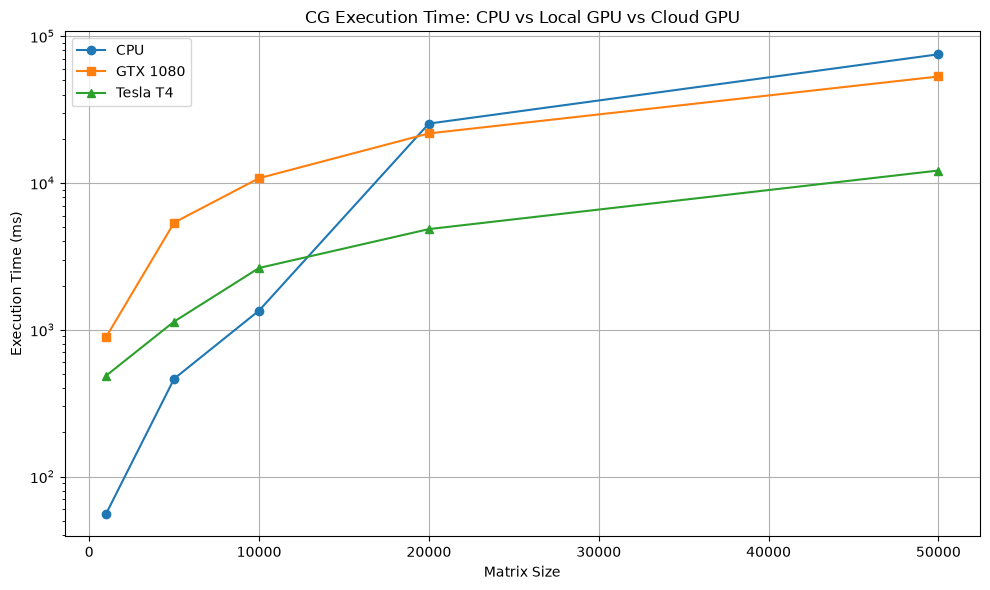

In [17]:
import matplotlib.pyplot as plt

# Execution time comparison
plt.figure(figsize=(10, 6))

plt.plot(comparison_df["Matrix_Size"],
         comparison_df["CPU_ms"], marker="o", label="CPU")

plt.plot(comparison_df["Matrix_Size"],
         comparison_df["GTX1080_ms"], marker="s", label="GTX 1080")

plt.plot(comparison_df["Matrix_Size"],
         comparison_df["T4_ms"], marker="^", label="Tesla T4")

plt.xlabel("Matrix Size")
plt.ylabel("Execution Time (ms)")
plt.title("CG Execution Time: CPU vs Local GPU vs Cloud GPU")
plt.yscale("log")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("cg_execution_time_comparison.png", dpi=300)
plt.show()

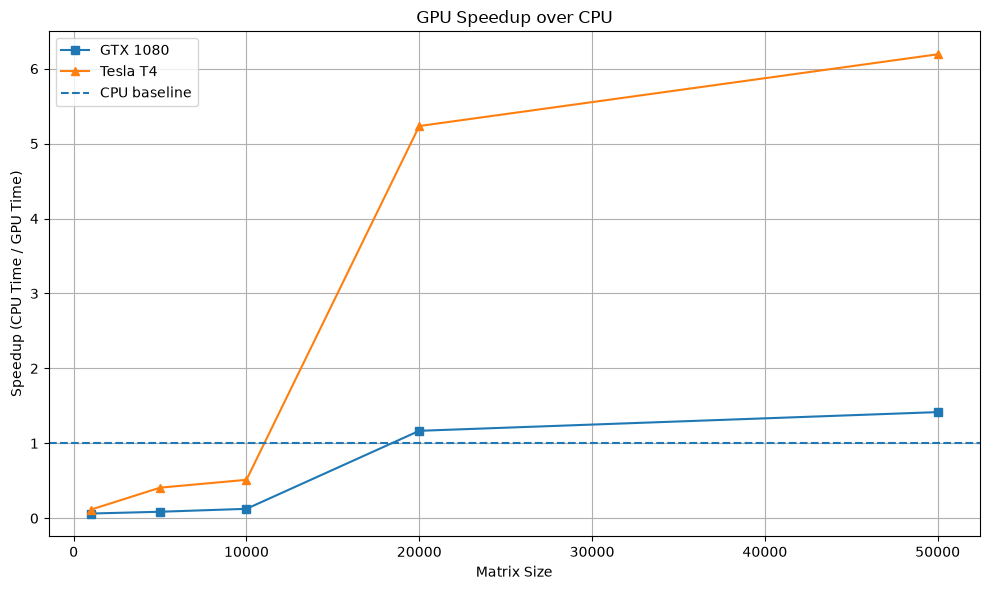

In [18]:
plt.figure(figsize=(10, 6))

plt.plot(comparison_df["Matrix_Size"],
         comparison_df["GTX1080_Speedup"],
         marker="s", label="GTX 1080")

plt.plot(comparison_df["Matrix_Size"],
         comparison_df["T4_Speedup"],
         marker="^", label="Tesla T4")

plt.axhline(y=1, linestyle="--", label="CPU baseline")

plt.xlabel("Matrix Size")
plt.ylabel("Speedup (CPU Time / GPU Time)")
plt.title("GPU Speedup over CPU")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("cg_speedup_comparison.png", dpi=300)
plt.show()